# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 2. PCA y evaluación de mejoras al modelo (Semana 14)

Profesor: Elias Buitrago Bolivar · Universidad Central · Caso: Brazilian E-Commerce Public Dataset by Olist

**Estudiante ID 01 · Semilla 1001**

**Pregunta de análisis:** ¿es preferible el modelo que registra más aciertos, el que identifica más entregas tardías o el que representa un menor costo para la empresa?

Se mantiene el problema, la muestra y las particiones de la semana 12. Los pedidos de prueba **no** se utilizan para elegir el modelo.

## 1. Importaciones

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy
from scipy.stats import ks_2samp

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})

## 2. Carga y preparación de datos

Es la misma preparación de la semana 12 (se repite para que el cuaderno pueda ejecutarse completo, desde cero, en Colab). Una observación es un pedido; no se incluyen fechas de entrega real ni reseñas entre los predictores.

In [2]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


In [3]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [4]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [5]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


In [6]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


In [7]:
# ID asignado por el profesor (01 se escribe 1). Es el mismo de la semana 12.
ID_ESTUDIANTE = 1
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 01 | Semilla: 1001
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 9e0cf0664d9d


## 3. Parámetros comunes del experimento

Se fijan una sola vez para que los cuatro modelos sean comparables: cambian **solo** la reducción de dimensionalidad y la fuerza de la regularización.

In [8]:
UMBRAL = 0.50              # umbral de clasificación común a los cuatro modelos
CLASS_WEIGHT = 'balanced'  # igual en A, B, C y D
VARIANZA_OBJETIVO = 0.90   # varianza mínima que debe explicar PCA
COSTO_FP, COSTO_FN = 8, 35 # supuesto didáctico (R$); NO son costos observados de Olist
ALPHA = 0.05               # nivel de significancia de la prueba KS

REPORTS = Path('reports')
REPORTS.mkdir(parents=True, exist_ok=True)

n_tardias_valid = int(y_valid.sum())
print('Pedidos de validación:', len(y_valid), '| tardíos:', n_tardias_valid,
      f'({100 * y_valid.mean():.2f} %)')

Pedidos de validación: 5250 | tardíos: 355 (6.76 %)


## 4. Actividad 1. PCA: curva de varianza explicada acumulada

Orden de las transformaciones numéricas: **imputar (mediana) → estandarizar → PCA**. Los tres pasos se ajustan **solo con entrenamiento**; validación únicamente se transforma con lo aprendido, de modo que no hay fuga de información. PCA se aplica solo a las 24 variables numéricas; las 4 categóricas siguen su propia ruta (One-Hot).

Variables numéricas iniciales: 24
Componentes para explicar >= 90 %: 15
Varianza acumulada con 15 componentes: 90.64 %
Varianza descartada: 9.36 %
Varianza acumulada con 1, 2, 3, 5, 10 componentes (%): {1: 19.4, 2: 29.0, 3: 36.7, 5: 51.4, 10: 73.3}
Verificado: la varianza explicada de PCA coincide con s^2/(n-1) de la SVD.


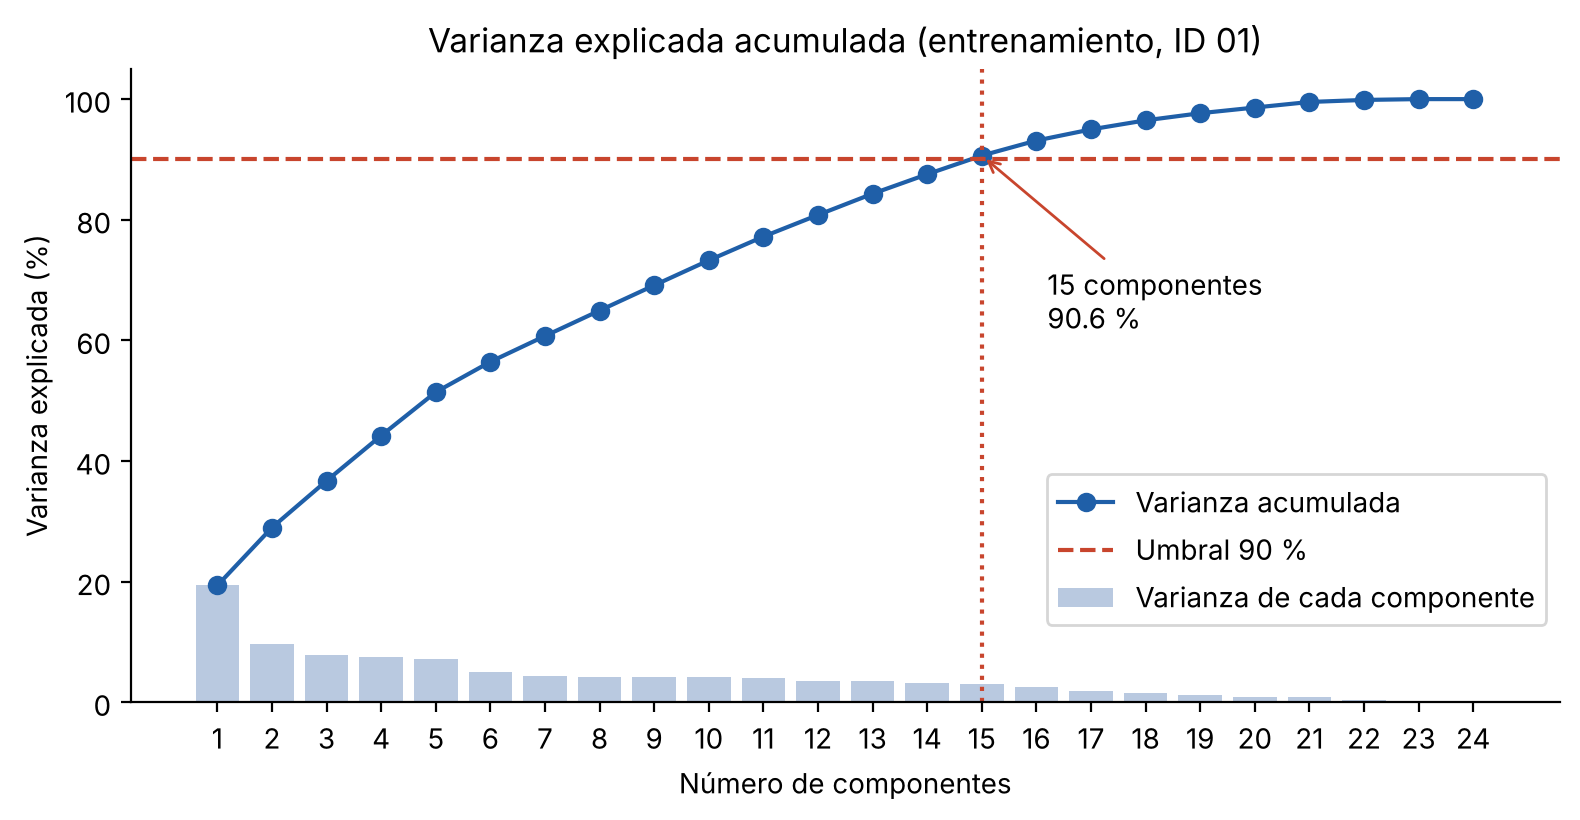

In [9]:
# Ajuste de imputación, escala y PCA SOLO con entrenamiento.
imputador = SimpleImputer(strategy='median').fit(X_train[columnas_numericas])
escalador = StandardScaler().fit(imputador.transform(X_train[columnas_numericas]))
Z_train = escalador.transform(imputador.transform(X_train[columnas_numericas]))

pca_completo = PCA(svd_solver='full').fit(Z_train)   # SVD sobre la matriz centrada
var_ratio = pca_completo.explained_variance_ratio_
var_acumulada = np.cumsum(var_ratio)

n_variables_numericas = len(columnas_numericas)
# Número mínimo de componentes con varianza acumulada >= 90 %.
n_componentes_90 = int(np.argmax(var_acumulada >= VARIANZA_OBJETIVO) + 1)
varianza_retenida = float(var_acumulada[n_componentes_90 - 1])

print('Variables numéricas iniciales:', n_variables_numericas)
print('Componentes para explicar >= 90 %:', n_componentes_90)
print(f'Varianza acumulada con {n_componentes_90} componentes: {100 * varianza_retenida:.2f} %')
print(f'Varianza descartada: {100 * (1 - varianza_retenida):.2f} %')

# Relación SVD <-> PCA: varianza de la componente j = s_j^2 / (n - 1).
_, s, _ = np.linalg.svd(Z_train, full_matrices=False)
var_svd = s ** 2 / (len(Z_train) - 1)
assert np.allclose(var_svd / var_svd.sum(), var_ratio), 'SVD y PCA deberían coincidir.'
print('Varianza acumulada con 1, 2, 3, 5, 10 componentes (%):',
      {k: round(float(100 * var_acumulada[k - 1]), 1) for k in (1, 2, 3, 5, 10)})
print('Verificado: la varianza explicada de PCA coincide con s^2/(n-1) de la SVD.')

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(1, n_variables_numericas + 1)
ax.bar(x, 100 * var_ratio, color='#b9c9e0', label='Varianza de cada componente')
ax.plot(x, 100 * var_acumulada, 'o-', color='#1f5fa8', label='Varianza acumulada')
ax.axhline(100 * VARIANZA_OBJETIVO, ls='--', color='#c8452d', label='Umbral 90 %')
ax.axvline(n_componentes_90, ls=':', color='#c8452d')
ax.annotate(f'{n_componentes_90} componentes\n{100 * varianza_retenida:.1f} %',
            (n_componentes_90, 100 * varianza_retenida), xytext=(n_componentes_90 + 1.2, 62),
            arrowprops=dict(arrowstyle='->', color='#c8452d'))
ax.set_xlabel('Número de componentes'); ax.set_ylabel('Varianza explicada (%)')
ax.set_title(f'Varianza explicada acumulada (entrenamiento, ID {identificador})')
ax.set_xticks(x); ax.legend(loc='lower right', bbox_to_anchor=(1.0, 0.1))
fig.tight_layout()
fig.savefig(REPORTS / f'S14_varianza_acumulada_ID_{identificador}.png', dpi=150)
plt.show()

In [10]:
# ¿Qué significan las componentes y qué información se pierde?
cargas = pd.DataFrame(pca_completo.components_[:n_componentes_90].T,
                      index=columnas_numericas,
                      columns=[f'CP{i + 1}' for i in range(n_componentes_90)])
print('Variables con mayor peso (valor absoluto) en las 3 primeras componentes:')
for cp in ['CP1', 'CP2', 'CP3']:
    top = cargas[cp].abs().sort_values(ascending=False).head(4).index
    print(f'  {cp} ({100 * var_ratio[int(cp[2:]) - 1]:.1f} %):',
          ', '.join(f'{v} ({cargas.loc[v, cp]:+.2f})' for v in top))

# Fracción de la varianza de cada variable que conservan las componentes retenidas.
lam = pca_completo.explained_variance_[:n_componentes_90]
retenida_por_variable = pd.Series(
    (cargas.values ** 2 * lam).sum(axis=1) / pca_completo.explained_variance_.sum() * n_variables_numericas,
    index=columnas_numericas).sort_values()
print('\nVariables que más información propia pierden al comprimir (fracción de su varianza retenida):')
print(retenida_por_variable.head(6).round(3).to_string())

Variables con mayor peso (valor absoluto) en las 3 primeras componentes:
  CP1 (19.4 %): valor_pagado (+0.40), valor_productos (+0.39), peso_total_g (+0.36), precio_maximo (+0.35)
  CP2 (9.6 %): cantidad_items (+0.37), proporcion_flete (+0.36), precio_maximo (-0.35), cantidad_productos (+0.34)
  CP3 (7.8 %): vendedor_mismo_estado (+0.48), dias_prometidos (-0.47), dia_semana_compra (-0.36), compra_fin_semana (-0.35)

Variables que más información propia pierden al comprimir (fracción de su varianza retenida):
proporcion_flete         0.650
dias_prometidos          0.740
vendedor_mismo_estado    0.758
valor_flete              0.789
cantidad_productos       0.815
volumen_total_cm3        0.833


### Interpretación (Actividad 1)

- **Reducción obtenida.** Se partió de **24 variables numéricas** y se conservaron **15 componentes** para explicar al menos el 90 % de la varianza (quedan 90,64 %). Se descarta el 9,36 % de la variabilidad. La curva crece despacio: 1 componente explica solo el 19,4 % y hacen falta 15 para llegar al 90 %, lo que indica que las variables numéricas no son tan redundantes como podría esperarse. Además, el clasificador pasa de 151 a 142 columnas (solo 9 menos) porque las 127 columnas One-Hot de las categóricas no se comprimen.
- **Qué significan las componentes.** CP1 (19,4 %) agrupa el tamaño y valor del pedido (`valor_pagado`, `valor_productos`, `peso_total_g`, `precio_maximo`). CP2 (9,6 %) contrasta la cantidad de ítems y el peso del flete con el precio máximo. CP3 (7,8 %) opone `vendedor_mismo_estado` a `dias_prometidos` y al calendario de compra. Los pesos describen combinaciones lineales, no causas, y cada componente mezcla variables de distinta naturaleza.
- **Qué información puede perderse.** La varianza descartada no es "ruido" por definición. Las variables cuya varianza propia queda peor representada son `proporcion_flete` (65 % retenida), `dias_prometidos` (74 %), `vendedor_mismo_estado` (76 %) y `valor_flete` (79 %). Varias de ellas (el plazo prometido y la cercanía vendedor-cliente) son justamente candidatas a explicar un retraso, así que comprimirlas podría perjudicar la predicción, algo que se comprueba en la Actividad 2.
- **Utilidad para el problema.** PCA resume la varianza, no la capacidad de predecir `is_late`: el 90,64 % describe el espacio de variables, no es una exactitud. Con 24.500 pedidos y 151 columnas tampoco hay una necesidad evidente de reducir dimensión por costo computacional (el modelo converge en menos de 250 iteraciones).
- **Comprobación.** La varianza explicada por PCA coincide con `s²/(n−1)` de la descomposición SVD de la matriz estandarizada, lo que confirma la relación entre ambos métodos.


## 5. Actividad 2. Comparación de las cuatro configuraciones

| Experimento | Transformación numérica | `C` |
|---|---|---|
| A. Referencia | Sin PCA | 1,0 |
| B. Reducción de dimensión | PCA (90 % de varianza) | 1,0 |
| C. Mayor penalización | PCA (90 % de varianza) | 0,1 |
| D. Menor penalización | PCA (90 % de varianza) | 10,0 |

Todos usan la misma muestra, la misma partición, `class_weight='balanced'` y el umbral 0,50.

In [11]:
def construir_modelo(usar_pca, C):
    """Pipeline completo: ruta numérica (imputar, escalar, PCA opcional) + ruta categórica + regresión logística."""
    pasos_num = [SimpleImputer(strategy='median'), StandardScaler()]
    if usar_pca:
        pasos_num.append(PCA(n_components=n_componentes_90, svd_solver='full'))
    prep = ColumnTransformer([
        ('numericas', make_pipeline(*pasos_num), columnas_numericas),
        ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                      OneHotEncoder(handle_unknown='ignore')), columnas_categoricas),
    ])
    return make_pipeline(prep, LogisticRegression(C=C, class_weight=CLASS_WEIGHT, max_iter=1000))

configuraciones = {
    'A': dict(nombre='A. Sin PCA, C=1.0', usar_pca=False, C=1.0),
    'B': dict(nombre='B. PCA 90 %, C=1.0', usar_pca=True, C=1.0),
    'C': dict(nombre='C. PCA 90 %, C=0.1', usar_pca=True, C=0.1),
    'D': dict(nombre='D. PCA 90 %, C=10.0', usar_pca=True, C=10.0),
}

modelos, probas, filas = {}, {}, []
for clave, cfg in configuraciones.items():
    m = construir_modelo(cfg['usar_pca'], cfg['C'])
    m.fit(X_train, y_train)                                # se ajusta solo con entrenamiento
    p_valid = m.predict_proba(X_valid)[:, 1]
    p_train = m.predict_proba(X_train)[:, 1]
    pred_m = (p_valid >= UMBRAL).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_valid, pred_m, labels=[0, 1]).ravel()
    modelos[clave], probas[clave] = m, p_valid
    filas.append({
        'experimento': clave, 'nombre': cfg['nombre'], 'usa_pca': cfg['usar_pca'], 'C': cfg['C'],
        'n_componentes_pca': n_componentes_90 if cfg['usar_pca'] else np.nan,
        'n_columnas_modelo': int(m[0].transform(X_valid.head(5)).shape[1]),
        'accuracy': accuracy_score(y_valid, pred_m),
        'precision': precision_score(y_valid, pred_m, zero_division=0),
        'recall': recall_score(y_valid, pred_m, zero_division=0),
        'f1': f1_score(y_valid, pred_m, zero_division=0),
        'roc_auc': roc_auc_score(y_valid, p_valid),
        'ap': average_precision_score(y_valid, p_valid),
        'ap_train': average_precision_score(y_train, p_train),
        'tn': int(tn_), 'fp': int(fp_), 'fn': int(fn_), 'tp': int(tp_),
        'alertas': int(pred_m.sum()),
        'iteraciones': int(m[-1].n_iter_[0]),
    })

tabla = pd.DataFrame(filas).set_index('experimento', drop=False)
print('Entrenamiento terminado. Iteraciones usadas (max_iter=1000):',
      tabla['iteraciones'].to_dict())

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Entrenamiento terminado. Iteraciones usadas (max_iter=1000): {'A': 141, 'B': 164, 'C': 80, 'D': 246}


In [12]:
# Tabla comparativa en validación (umbral 0,50)
columnas_vista = ['nombre', 'n_columnas_modelo', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'ap', 'ap_train']
display(tabla[columnas_vista].round(4))

# Cambios respecto a la referencia A y respecto a B (una condición a la vez)
metricas = ['accuracy', 'precision', 'recall', 'f1', 'ap']
print('B - A (efecto de PCA):')
display((tabla.loc['B', metricas] - tabla.loc['A', metricas]).round(4).to_frame('diferencia').T)
print('C - B (penalización mayor) y D - B (penalización menor):')
display(pd.DataFrame({'C - B': tabla.loc['C', metricas] - tabla.loc['B', metricas],
                      'D - B': tabla.loc['D', metricas] - tabla.loc['B', metricas]}).T.round(4))

,nombre,n_columnas_modelo,accuracy,precision,recall,f1,roc_auc,ap,ap_train
experimento,,,,,,,,,
A,"A. Sin PCA, C=1.0",151,0.6686,0.1210,0.6225,0.2026,0.7074,0.1600,0.1719
B,"B. PCA 90 %, C=1.0",142,0.6392,0.1064,0.5859,0.1801,0.6609,0.1266,0.1489
C,"C. PCA 90 %, C=0.1",142,0.6421,0.1068,0.5831,0.1805,0.6637,0.1293,0.1492
D,"D. PCA 90 %, C=10.0",142,0.6366,0.1056,0.5859,0.1790,0.6606,0.1245,0.1491


B - A (efecto de PCA):


,accuracy,precision,recall,f1,ap
diferencia,-0.029333,-0.014569,-0.03662,-0.02248,-0.033376


C - B (penalización mayor) y D - B (penalización menor):


,accuracy,precision,recall,f1,ap
C - B,0.002857,0.000417,-0.002817,0.000463,0.002709
D - B,-0.002667,-0.000756,0.0,-0.001085,-0.002126


### Interpretación (Actividad 2)

| Experimento | Accuracy | Precision | Recall | F1 | AP |
|---|---|---|---|---|---|
| A. Sin PCA, C=1.0 | 0,669 | 0,121 | 0,623 | 0,203 | 0,160 |
| B. PCA 90 %, C=1.0 | 0,639 | 0,106 | 0,586 | 0,180 | 0,127 |
| C. PCA 90 %, C=0.1 | 0,642 | 0,107 | 0,583 | 0,181 | 0,129 |
| D. PCA 90 %, C=10.0 | 0,637 | 0,106 | 0,586 | 0,179 | 0,124 |

- **PCA (B frente a A).** Es el único cambio que importa y es negativo: PCA reduce la Accuracy 2,9 puntos, el Recall 3,7, el F1 2,2 y el AP 3,3 (ROC-AUC de 0,707 a 0,661). Comprimir de 24 a 15 componentes eliminó información útil para distinguir los retrasos, coherente con lo observado en la Actividad 1: la varianza descartada incluye parte del plazo prometido y de la ubicación del vendedor. Esto es una hipótesis consistente con los resultados, no una prueba de causa.
- **Regularización (C y D frente a B).** Cambiar `C` de 1,0 a 0,1 o a 10,0 mueve las métricas menos de 0,3 puntos (el Recall de D es idéntico al de B). Con 24.500 pedidos y pocas componentes, el modelo no depende de la fuerza de la penalización.
- **Sobreajuste.** No parece ser el problema: en A el AP es 0,172 en entrenamiento y 0,160 en validación, una brecha pequeña. Los modelos con PCA tampoco reducen esa brecha (0,149 y 0,127). El modelo está limitado por la señal disponible en las variables (AP cercano a 0,16 frente a una prevalencia de 0,068), no por exceso de ajuste.
- **Conclusión.** El modelo sin PCA supera a los tres modelos con PCA en todas las métricas. La Accuracy más baja de B, C y D, con más falsas alertas y menos retrasos detectados, no se compensa con ninguna otra ventaja. Ninguna de las cuatro configuraciones tiene una Precision alta (entre 0,106 y 0,121): de cada 100 alertas, solo 11 a 12 corresponden a un retraso real.


## 6. Actividad 3. Falsos positivos, falsos negativos y costo didáctico

Costo = `R$ 8 × FP + R$ 35 × FN` (supuesto didáctico; **no** son costos observados de Olist). Se compara además con una referencia externa: el modelo que **nunca alerta** (todas las entregas tardías serían falsos negativos).

,nombre,fp,fn,costo_fp_brl,costo_fn_brl,costo_brl
experimento,,,,,,
A,"A. Sin PCA, C=1.0",1606,134,12848,4690,17538
B,"B. PCA 90 %, C=1.0",1747,147,13976,5145,19121
C,"C. PCA 90 %, C=0.1",1731,148,13848,5180,19028
D,"D. PCA 90 %, C=10.0",1761,147,14088,5145,19233


Referencia externa "nunca alerta": FN = 355 -> R$ 12,425
Precisión de equilibrio frente a "nunca alerta": 18.6 %
Precisión de cada modelo (%): {'A': 12.1, 'B': 10.6, 'C': 10.7, 'D': 10.6}
Ahorro/(sobrecosto) frente a "nunca alerta" (R$): {'A': -5113, 'B': -6696, 'C': -6603, 'D': -6808}

Mayor Accuracy: A | Mayor Recall: A | Mayor F1: A | Mayor AP: A | Menor costo: A


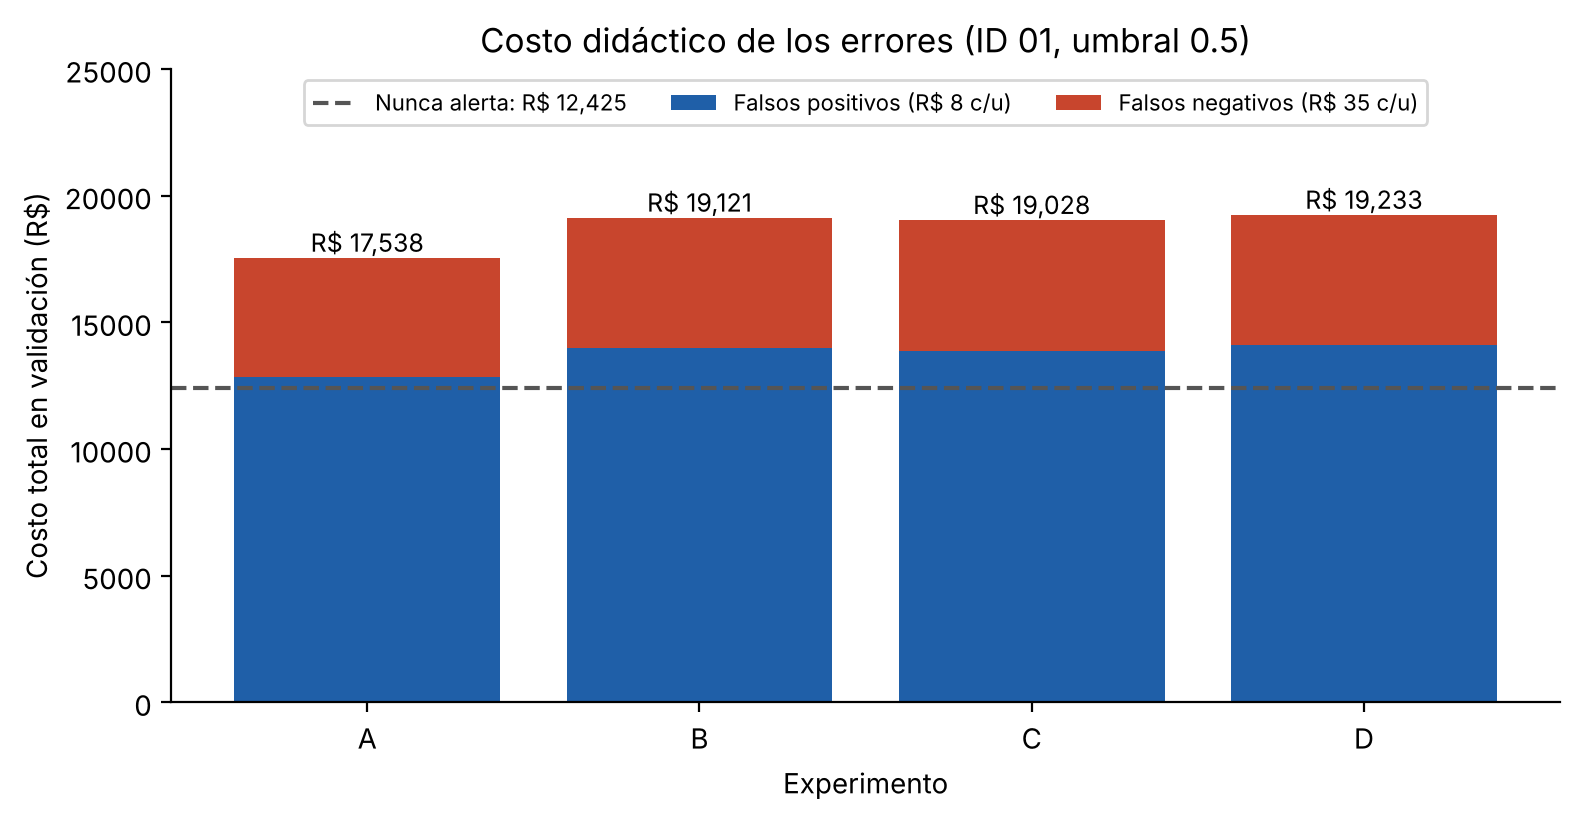

In [13]:
tabla['costo_fp_brl'] = COSTO_FP * tabla['fp']
tabla['costo_fn_brl'] = COSTO_FN * tabla['fn']
tabla['costo_brl'] = tabla['costo_fp_brl'] + tabla['costo_fn_brl']

costo_nunca_alerta = COSTO_FN * n_tardias_valid
display(tabla[['nombre', 'fp', 'fn', 'costo_fp_brl', 'costo_fn_brl', 'costo_brl']])
print(f'Referencia externa "nunca alerta": FN = {n_tardias_valid} -> R$ {costo_nunca_alerta:,.0f}')

# Precisión de equilibrio: una alerta compensa si 35 * precision > 8 * (1 - precision).
precision_equilibrio = COSTO_FP / (COSTO_FP + COSTO_FN)
print(f'Precisión de equilibrio frente a "nunca alerta": {100 * precision_equilibrio:.1f} %')
print('Precisión de cada modelo (%):', (100 * tabla['precision']).round(1).to_dict())
print('Ahorro/(sobrecosto) frente a "nunca alerta" (R$):', (costo_nunca_alerta - tabla['costo_brl']).to_dict())

mejor_costo = tabla['costo_brl'].idxmin()
mejor_recall = tabla['recall'].idxmax()
mejor_acc = tabla['accuracy'].idxmax()
mejor_f1 = tabla['f1'].idxmax()
mejor_ap = tabla['ap'].idxmax()
print('\nMayor Accuracy:', mejor_acc, '| Mayor Recall:', mejor_recall, '| Mayor F1:', mejor_f1,
      '| Mayor AP:', mejor_ap, '| Menor costo:', mejor_costo)

# Gráfico de costos
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(tabla['experimento'], tabla['costo_fp_brl'], color='#1f5fa8', label=f'Falsos positivos (R$ {COSTO_FP} c/u)')
ax.bar(tabla['experimento'], tabla['costo_fn_brl'], bottom=tabla['costo_fp_brl'], color='#c8452d',
       label=f'Falsos negativos (R$ {COSTO_FN} c/u)')
ax.axhline(costo_nunca_alerta, ls='--', color='#555', label=f'Nunca alerta: R$ {costo_nunca_alerta:,.0f}')
for i, v in enumerate(tabla['costo_brl']):
    ax.text(i, v + 250, f'R$ {v:,.0f}', ha='center', fontsize=9)
ax.set_ylabel('Costo total en validación (R$)'); ax.set_xlabel('Experimento')
ax.set_title(f'Costo didáctico de los errores (ID {identificador}, umbral {UMBRAL})')
ax.set_ylim(0, 1.3 * tabla['costo_brl'].max())
ax.legend(fontsize=8, loc='upper center', ncol=3)
fig.tight_layout()
fig.savefig(REPORTS / f'S14_costos_ID_{identificador}.png', dpi=150)
plt.show()

In [14]:
# Verificación complementaria: ¿la diferencia de costo frente a A es mayor que el ruido de muestreo?
# Remuestreo (bootstrap) pareado sobre los pedidos de validación; no sustituye una prueba formal.
rng = np.random.default_rng(semilla)
idx = rng.integers(0, len(y_valid), size=(2000, len(y_valid)))
costo_por_pedido = {}
for clave in tabla.index:
    p = (probas[clave] >= UMBRAL).astype(int)
    costo_por_pedido[clave] = COSTO_FP * ((p == 1) & (y_valid.values == 0)) + COSTO_FN * ((p == 0) & (y_valid.values == 1))
filas_bs = []
for clave in ['B', 'C', 'D']:
    dif = (costo_por_pedido[clave] - costo_por_pedido['A'])[idx].sum(axis=1)
    lo, hi = np.percentile(dif, [2.5, 97.5])
    filas_bs.append({'comparación': f'{clave} - A', 'dif_costo_observada': int(costo_por_pedido[clave].sum() - costo_por_pedido['A'].sum()),
                     'IC95_inf': round(lo), 'IC95_sup': round(hi), 'IC_incluye_0': bool(lo <= 0 <= hi)})
intervalos_costo = pd.DataFrame(filas_bs)
display(intervalos_costo)

,comparación,dif_costo_observada,IC95_inf,IC95_sup,IC_incluye_0
0,B - A,1583,946,2238,False
1,C - A,1490,864,2147,False
2,D - A,1695,1058,2369,False


### Interpretación (Actividad 3)

| Experimento | FP | FN | Costo por FP | Costo por FN | **Costo total** |
|---|---|---|---|---|---|
| A. Sin PCA, C=1.0 | 1.606 | 134 | R$ 12.848 | R$ 4.690 | **R$ 17.538** |
| B. PCA 90 %, C=1.0 | 1.747 | 147 | R$ 13.976 | R$ 5.145 | **R$ 19.121** |
| C. PCA 90 %, C=0.1 | 1.731 | 148 | R$ 13.848 | R$ 5.180 | **R$ 19.028** |
| D. PCA 90 %, C=10.0 | 1.761 | 147 | R$ 14.088 | R$ 5.145 | **R$ 19.233** |
| Referencia "nunca alerta" | 0 | 355 | R$ 0 | R$ 12.425 | **R$ 12.425** |

- **Hechos observados.** El modelo A tiene a la vez la mayor Accuracy, el mayor Recall, el mayor F1, el mayor AP y el menor costo de los cuatro (R$ 17.538). Los tres criterios de la pregunta de análisis (más aciertos, más tardías detectadas, menor costo) coinciden en A. PCA añade unos 140 falsos positivos y 13 falsos negativos más, lo que cuesta R$ 1.583 adicionales (B frente a A). Entre B, C y D las diferencias de costo (R$ 93 y R$ 112) son marginales.
- **Verificación del ruido.** Un remuestreo (bootstrap) pareado de los 5.250 pedidos de validación da para B − A un intervalo de R$ 946 a R$ 2.238, y para C − A y D − A intervalos similares, todos por encima de cero. La ventaja de A no parece deberse solo al azar de la validación. Esta comprobación no incluye la variabilidad del entrenamiento ni sustituye una validación cruzada, y no se contrastó formalmente B, C y D entre sí: sus diferencias son tan pequeñas que no permiten afirmar que unas sean mejores que otras.
- **Decisión empresarial.** Entre las cuatro alternativas elijo **A (sin PCA, C=1,0)**: es la mejor en todos los criterios, es la más simple (sin una transformación que descarta información) y es idéntica al modelo de la semana 12, por lo que sirve de base comparable. No hay razón para adoptar PCA en este problema.
- **Advertencia importante.** Ni siquiera A es rentable con estos supuestos: cuesta R$ 5.113 más que no alertar nunca (R$ 12.425). Una alerta compensa solo si la precisión supera 8/(8+35) = 18,6 %, y la de A es 12,1 %. Es decir, con un umbral de 0,50 y costos de R$ 8 y R$ 35, el modelo no justificaría una intervención operativa. Elegir A significa elegir el mejor candidato, no declarar que el sistema ya es útil. Una mejora razonable es un umbral más alto o variables más informativas, pero cambiar el umbral sería otro experimento y no se hizo aquí.
- **Limitaciones.** Los costos de R$ 8 y R$ 35 son supuestos didácticos, no costos de Olist, y no incluyen el costo fijo de operar el sistema; todo se evaluó en una sola partición aleatoria de validación.


## 7. Actividad 4. Prueba de Kolmogorov-Smirnov sobre `valor_flete`

Se contrasta si la distribución de `valor_flete` es compatible entre **entrenamiento** y **validación**.

- **H0:** `valor_flete` procede de la misma distribución en entrenamiento y validación.
- **H1:** las distribuciones de `valor_flete` en ambos conjuntos son diferentes (prueba bilateral).
- **Nivel de significancia:** α = 0,05.

La prueba compara particiones, **no** modelos.

n entrenamiento = 24,500 | n validación = 5,250
Estadístico D = 0.0131 | valor p = 0.4455 | D crítico (aprox., 5 %) = 0.0207
Decisión al 5 %: No rechazar H0
D calculado a mano con las ECDF = 0.0131 (alcanzado en valor_flete = 29.84)


,entrenamiento,validación
count,24500.00,5250.00
mean,22.71,22.65
std,23.38,19.72
min,0.00,0.00
25%,13.86,13.77
50%,17.09,17.17
75%,23.85,24.46
95%,54.42,53.26
max,1794.96,371.46


Valores repetidos en entrenamiento (empates): 81.2 % de las observaciones


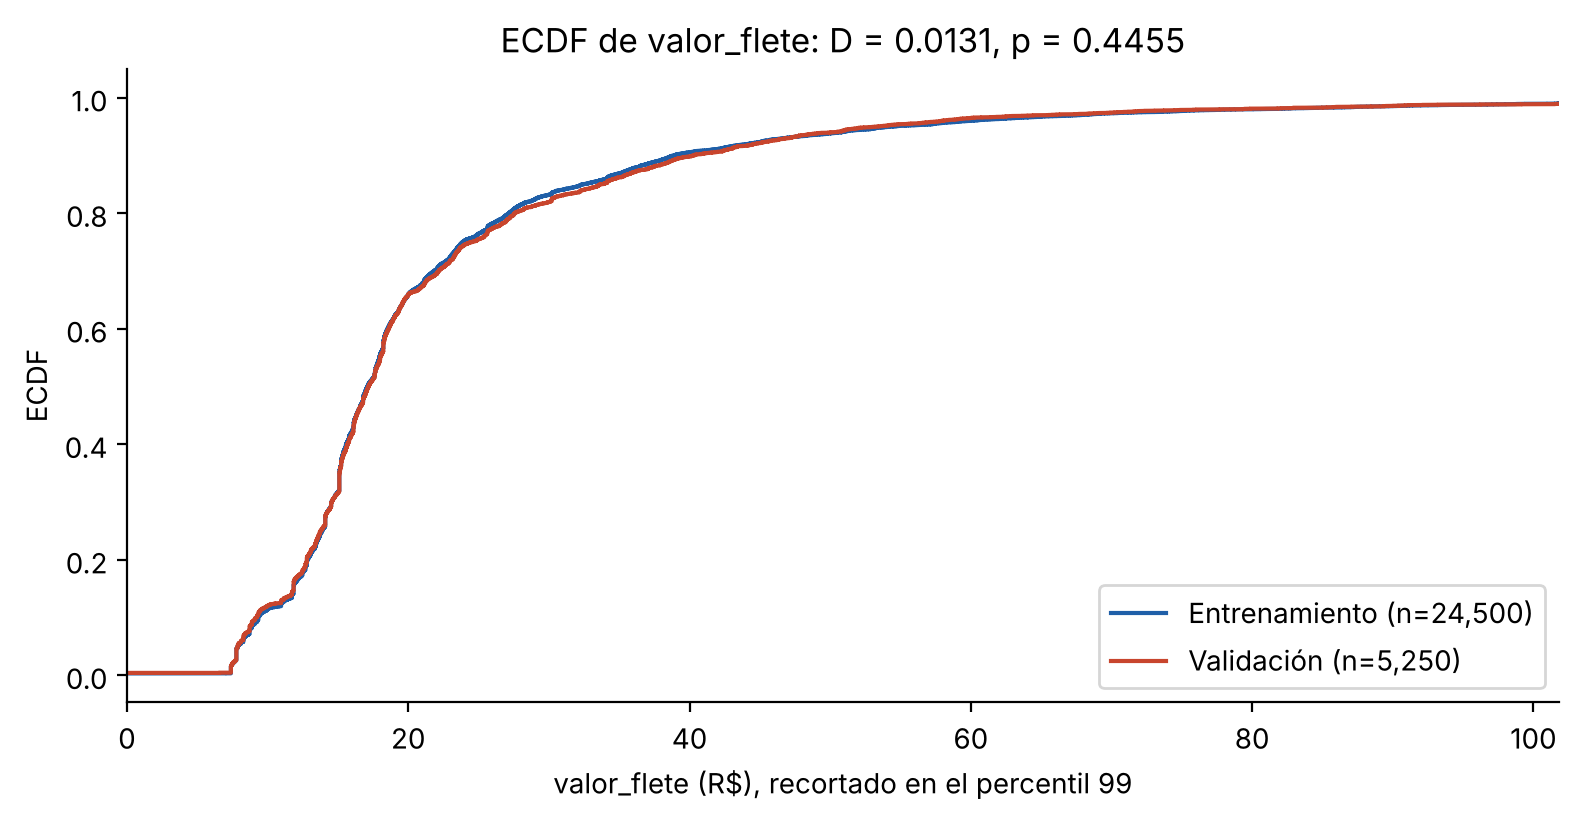

In [15]:
flete_train = train['valor_flete'].dropna()
flete_valid = valid['valor_flete'].dropna()

resultado_ks = ks_2samp(flete_train, flete_valid, alternative='two-sided')
D_ks, p_ks = float(resultado_ks.statistic), float(resultado_ks.pvalue)
n1, n2 = len(flete_train), len(flete_valid)
D_critico = 1.358 * np.sqrt((n1 + n2) / (n1 * n2))   # valor crítico aproximado para alpha = 0.05
decision_ks = 'Rechazar H0' if p_ks < ALPHA else 'No rechazar H0'

print(f'n entrenamiento = {n1:,} | n validación = {n2:,}')
print(f'Estadístico D = {D_ks:.4f} | valor p = {p_ks:.4f} | D crítico (aprox., 5 %) = {D_critico:.4f}')
print('Decisión al 5 %:', decision_ks)

# Comprobación manual de D con las ECDF.
a, b = np.sort(flete_train.values), np.sort(flete_valid.values)
rejilla = np.unique(np.concatenate([a, b]))
Fa = np.searchsorted(a, rejilla, side='right') / n1
Fb = np.searchsorted(b, rejilla, side='right') / n2
D_manual = float(np.max(np.abs(Fa - Fb)))
x_D = rejilla[np.argmax(np.abs(Fa - Fb))]
assert np.isclose(D_manual, D_ks), 'D calculado a mano no coincide con scipy.'
print(f'D calculado a mano con las ECDF = {D_manual:.4f} (alcanzado en valor_flete = {x_D:.2f})')

descriptivas = pd.DataFrame({
    'entrenamiento': flete_train.describe(percentiles=[.25, .5, .75, .95]),
    'validación': flete_valid.describe(percentiles=[.25, .5, .75, .95])}).round(2)
display(descriptivas)
empates = 100 * (1 - flete_train.nunique() / n1)
print(f'Valores repetidos en entrenamiento (empates): {empates:.1f} % de las observaciones')

fig, ax = plt.subplots(figsize=(8, 4.2))
lim = np.percentile(np.concatenate([a, b]), 99)
ax.step(rejilla, Fa, where='post', color='#1f5fa8', label=f'Entrenamiento (n={n1:,})')
ax.step(rejilla, Fb, where='post', color='#c8452d', label=f'Validación (n={n2:,})')
ax.set_xlim(0, lim); ax.set_xlabel('valor_flete (R$), recortado en el percentil 99'); ax.set_ylabel('ECDF')
ax.set_title(f'ECDF de valor_flete: D = {D_ks:.4f}, p = {p_ks:.4f}')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(REPORTS / f'S14_ecdf_valor_flete_ID_{identificador}.png', dpi=150)
plt.show()

### Interpretación (Actividad 4)

- **Resultado.** Con 24.500 pedidos de entrenamiento y 5.250 de validación, el estadístico es **D = 0,0131** y el valor p es **0,4455**. Como p ≥ 0,05, **no se rechaza H0** al 5 %: no hay evidencia suficiente de que la distribución de `valor_flete` difiera entre ambas particiones. Coherente con esto, D es menor que el valor crítico aproximado (0,0207). El D calculado a mano con las ECDF (0,0131, alcanzado en `valor_flete` ≈ 29,84) coincide con el de SciPy.
- **Descriptivos.** Las medianas son casi iguales (17,09 y 17,17), igual que los cuartiles (Q1 13,86 y 13,77; Q3 23,85 y 24,46) y el percentil 95 (54,42 y 53,26). La ECDF de ambos grupos se superpone casi por completo.
- **Qué NO se puede concluir.** No rechazar H0 no demuestra que las distribuciones sean idénticas, solo que esta muestra no detecta diferencia. La prueba compara una variable entre dos particiones: no compara modelos, no dice si A es mejor que B y no valida el clasificador. Tampoco garantiza que la partición represente a pedidos futuros.
- **Limitación metodológica.** La prueba KS clásica supone una variable continua, pero `valor_flete` tiene un 81 % de observaciones con valores repetidos (importes redondeados a centavos y tarifas iguales), por lo que el valor p es aproximado y debe leerse con cautela. Además, KS es poco sensible a diferencias en las colas: el flete máximo es 1.794,96 en entrenamiento y 371,46 en validación, y la desviación estándar difiere (23,38 frente a 19,72) sin que D lo refleje. Con muestras grandes, la prueba también puede detectar diferencias mínimas sin relevancia operativa; aquí ocurre lo contrario, D es muy pequeño.
- **Implicación.** Para esta variable la partición aleatoria se comporta de forma similar en entrenamiento y validación, lo que respalda comparar los modelos A-D en validación. No sustituye una evaluación respetando el orden temporal de los pedidos.


## Conclusión general

**Pregunta de análisis: ¿más aciertos, más tardías detectadas o menor costo?** En esta muestra los tres criterios coinciden en la misma configuración entre las cuatro evaluadas (**A: sin PCA, `C=1,0`**), pero ninguno basta por sí solo: el modelo de referencia que nunca alerta tiene la mayor Accuracy (0,932) y un costo (R$ 12.425) menor que cualquiera de los cuatro.

1. **PCA no mejoró el modelo.** Retener 15 de 24 componentes (90,64 % de varianza) empeoró Recall, F1, AP y costo. Maximizar varianza no es lo mismo que maximizar capacidad predictiva.
2. **La regularización fue irrelevante.** `C = 0,1; 1,0; 10,0` produjo diferencias menores a 0,3 puntos y de R$ 112 en costo. El problema no es sobreajuste sino señal limitada (AP ≈ 0,16).
3. **Decisión:** adoptar A como modelo de la semana 14 y descartar PCA. Con costos de R$ 8 y R$ 35 y umbral 0,50 no compensa operar alertas (precisión 12,1 % frente a 18,6 % de equilibrio), por lo que el siguiente paso útil es mejorar la información (por ejemplo, ruta vendedor-cliente) y estudiar el umbral como experimento aparte.
4. **KS:** `valor_flete` no muestra diferencia detectable entre entrenamiento y validación (D = 0,0131; p = 0,4455), lo que respalda la comparación sin demostrar equivalencia ni validar el modelo.

La partición de prueba permanece intacta para la evaluación final de la semana 16.


## 8. Registro de experimentos y resumen (carpeta `reports/`)

Se guardan la bitácora de experimentos (CSV), el reporte JSON con la huella de la muestra, un resumen en Markdown generado con los valores calculados y las figuras. **No** se guardan la muestra de pedidos ni los datos originales.

In [16]:
modelo_elegido = mejor_costo   # criterio de costo; la justificación completa está en la Actividad 3

# 1) Bitácora de experimentos (CSV)
bitacora = tabla.copy()
bitacora.insert(0, 'id_estudiante', identificador)
bitacora.insert(1, 'semilla', semilla)
bitacora.insert(2, 'huella_muestra', huella_muestra)
bitacora['umbral'] = UMBRAL
bitacora['class_weight'] = CLASS_WEIGHT
bitacora['elegido'] = bitacora['experimento'] == modelo_elegido
ruta_csv = REPORTS / f'S14_experimentos_ID_{identificador}.csv'
bitacora.drop(columns=['experimento']).round(6).to_csv(ruta_csv, index_label='experimento')

# 2) Reporte JSON
reporte = {
    'laboratorio': 'S14',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.now(tz='UTC').isoformat(),
    'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
    'sklearn': sklearn.__version__, 'scipy': scipy.__version__,
    'n_muestra': len(muestra), 'n_train': len(train), 'n_valid': len(valid), 'n_test': len(test),
    'huella_muestra': huella_muestra,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'umbral': UMBRAL, 'class_weight': CLASS_WEIGHT,
    'costo_fp_brl': COSTO_FP, 'costo_fn_brl': COSTO_FN,
    'pca': {'n_variables_numericas': n_variables_numericas,
            'n_componentes_90': n_componentes_90,
            'varianza_acumulada': float(varianza_retenida)},
    'experimentos': {k: {c: (float(v) if isinstance(v, (float, np.floating)) else
                             (bool(v) if isinstance(v, (bool, np.bool_)) else
                              (int(v) if isinstance(v, (int, np.integer)) else str(v))))
                         for c, v in tabla.loc[k, ['nombre', 'usa_pca', 'C', 'accuracy', 'precision', 'recall', 'f1',
                                                  'roc_auc', 'ap', 'fp', 'fn', 'costo_brl']].items()}
                     for k in tabla.index},
    'costo_nunca_alerta_brl': int(costo_nunca_alerta),
    'modelo_elegido': modelo_elegido,
    'ks_valor_flete': {'D': D_ks, 'p_valor': p_ks, 'alpha': ALPHA, 'n_train': n1, 'n_valid': n2,
                       'D_critico_aprox': float(D_critico), 'decision': decision_ks},
}
ruta_json = REPORTS / f'S14_resultados_ID_{identificador}.json'
ruta_json.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')

# 3) Resumen en Markdown con los valores calculados
def fila_md(k):
    r = tabla.loc[k]
    return (f"| {r['nombre']} | {r['accuracy']:.3f} | {r['precision']:.3f} | {r['recall']:.3f} | {r['f1']:.3f} | "
            f"{r['ap']:.3f} | {int(r['fp']):,} | {int(r['fn']):,} | R$ {int(r['costo_brl']):,} |")

resumen = f"""# Laboratorio 2 (S14) · Resumen — ID {identificador}

**Muestra:** semilla {semilla}, huella `{huella_muestra}` · {len(train):,} entrenamiento / {len(valid):,} validación / {len(test):,} prueba (reservada).
**Condiciones comunes:** `class_weight='{CLASS_WEIGHT}'`, umbral {UMBRAL}, costos supuestos R$ {COSTO_FP} por FP y R$ {COSTO_FN} por FN.

## PCA
- Variables numéricas iniciales: **{n_variables_numericas}**; componentes para explicar al menos 90 %: **{n_componentes_90}** ({100 * varianza_retenida:.2f} % de varianza; se descarta {100 * (1 - varianza_retenida):.2f} %).
- Columnas que recibe el clasificador: {int(tabla.loc['A', 'n_columnas_modelo'])} sin PCA y {int(tabla.loc['B', 'n_columnas_modelo'])} con PCA (las categóricas aportan la mayoría).

![Varianza acumulada](S14_varianza_acumulada_ID_{identificador}.png)

## Comparación en validación (umbral {UMBRAL})
| Experimento | Accuracy | Precision | Recall | F1 | AP | FP | FN | Costo |
|---|---|---|---|---|---|---|---|---|
{chr(10).join(fila_md(k) for k in tabla.index)}

Referencia externa "nunca alerta": Accuracy {1 - y_valid.mean():.3f}, Recall 0, costo **R$ {int(costo_nunca_alerta):,}**.

![Costos](S14_costos_ID_{identificador}.png)

- Mayor Accuracy: **{mejor_acc}** · mayor Recall: **{mejor_recall}** · mayor F1: **{mejor_f1}** · mayor AP: **{mejor_ap}** · menor costo: **{mejor_costo}**.
- Efecto de PCA (B frente a A): Recall {tabla.loc['B', 'recall'] - tabla.loc['A', 'recall']:+.3f}, F1 {tabla.loc['B', 'f1'] - tabla.loc['A', 'f1']:+.3f}, AP {tabla.loc['B', 'ap'] - tabla.loc['A', 'ap']:+.3f}, costo R$ {int(tabla.loc['B', 'costo_brl'] - tabla.loc['A', 'costo_brl']):+,}.
- Efecto de C (C y D frente a B): diferencias de costo de R$ {int(tabla.loc['C', 'costo_brl'] - tabla.loc['B', 'costo_brl']):+,} y R$ {int(tabla.loc['D', 'costo_brl'] - tabla.loc['B', 'costo_brl']):+,}, es decir, marginales.
- **Modelo elegido entre los cuatro: {modelo_elegido}.** Aun así, su costo supera el de "nunca alerta" (precisión {100 * tabla.loc[modelo_elegido, 'precision']:.1f} % frente a una precisión de equilibrio de {100 * precision_equilibrio:.1f} %), por lo que con estos costos supuestos no justificaría una intervención con umbral {UMBRAL}.

## Kolmogorov-Smirnov sobre `valor_flete` (entrenamiento vs validación)
- n = {n1:,} y {n2:,} · **D = {D_ks:.4f}** · **p = {p_ks:.4f}** · α = {ALPHA} → **{decision_ks}**.
- No se rechaza H0, pero eso no demuestra que las distribuciones sean idénticas ni valida el modelo. Hay muchos valores repetidos ({empates:.0f} %), por lo que el valor p es aproximado.

![ECDF](S14_ecdf_valor_flete_ID_{identificador}.png)

## Archivos
`S14_experimentos_ID_{identificador}.csv`, `S14_resultados_ID_{identificador}.json` y las tres figuras. No se publican los datos originales ni la muestra de pedidos.
"""
ruta_md = REPORTS / f'S14_resumen_ID_{identificador}.md'
ruta_md.write_text(resumen, encoding='utf-8')
print('Guardados en', REPORTS.resolve(), ':', sorted(p.name for p in REPORTS.glob('S14_*')))


Guardados en /home/claude/s14/reports : ['S14_costos_ID_01.png', 'S14_ecdf_valor_flete_ID_01.png', 'S14_experimentos_ID_01.csv', 'S14_resultados_ID_01.json', 'S14_resumen_ID_01.md', 'S14_varianza_acumulada_ID_01.png']


## 9. Autoverificación

In [17]:
# Particiones
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), 'Particiones esperadas: 24500 / 5250 / 5250.'
assert set(train['order_id']).isdisjoint(valid['order_id']) and set(train['order_id']).isdisjoint(test['order_id']) \
       and set(valid['order_id']).isdisjoint(test['order_id']), 'Hay pedidos compartidos entre particiones.'

# Diseño del experimento
assert list(tabla.index) == ['A', 'B', 'C', 'D'], 'Deben existir los experimentos A, B, C y D.'
assert tabla.loc['A', 'usa_pca'] == False and tabla.loc[['B', 'C', 'D'], 'usa_pca'].all()
assert list(tabla['C']) == [1.0, 1.0, 0.1, 10.0], 'Valores de C esperados: 1.0, 1.0, 0.1, 10.0.'
assert all(m[-1].class_weight == 'balanced' for m in modelos.values()), 'Todos deben usar class_weight=balanced.'
assert all(m[-1].n_iter_[0] < 1000 for m in modelos.values()), 'Algún modelo agotó max_iter.'
assert all(np.array_equal(m.predict(X_valid), (p >= UMBRAL).astype(int))
           for m, p in zip(modelos.values(), probas.values())), 'Las predicciones no corresponden al umbral 0,50.'
for clave, fila in tabla.iterrows():
    assert fila['tp'] + fila['fn'] == n_tardias_valid
    assert fila['fp'] + fila['tn'] + fila['tp'] + fila['fn'] == len(y_valid)
    assert fila['costo_brl'] == COSTO_FP * fila['fp'] + COSTO_FN * fila['fn'], f'Costo incorrecto en {clave}.'

# PCA
assert 0 < n_componentes_90 < n_variables_numericas
assert var_acumulada[n_componentes_90 - 1] >= VARIANZA_OBJETIVO > (var_acumulada[n_componentes_90 - 2] if n_componentes_90 > 1 else 0)
assert all(not tabla.loc[k, 'n_componentes_pca'] != n_componentes_90 for k in ['B', 'C', 'D'])

# KS
assert 0 <= D_ks <= 1 and 0 <= p_ks <= 1

# Coherencia con la semana 12 (la configuración A repite la de S12 con class_weight='balanced')
ruta_s12 = REPORTS / f'S12_resultados_ID_{identificador}.json'
if ruta_s12.exists():
    s12_rep = json.loads(ruta_s12.read_text(encoding='utf-8'))
    assert s12_rep['huella_muestra'] == huella_muestra, 'La huella de la muestra cambió respecto a S12.'
    if s12_rep['peso_clases'] == 'balanced':
        assert np.isclose(s12_rep['metricas']['recall'], tabla.loc['A', 'recall']), 'A no coincide con S12.'
        assert s12_rep['costo_errores_brl'] == tabla.loc['A', 'costo_brl'], 'El costo de A no coincide con S12.'
        print('A reproduce exactamente el modelo de la semana 12.')
else:
    print('(No se encontró el JSON de S12; se omite la comparación con la semana 12.)')

# Archivos de reports/
for nombre in [f'S14_experimentos_ID_{identificador}.csv', f'S14_resultados_ID_{identificador}.json',
               f'S14_resumen_ID_{identificador}.md', f'S14_varianza_acumulada_ID_{identificador}.png',
               f'S14_costos_ID_{identificador}.png', f'S14_ecdf_valor_flete_ID_{identificador}.png']:
    ruta_a = REPORTS / nombre
    assert ruta_a.exists() and ruta_a.stat().st_size > 0, f'Falta {nombre}.'
print('Autoverificación superada.')


A reproduce exactamente el modelo de la semana 12.
Autoverificación superada.
